<a href="https://colab.research.google.com/github/juuuuuuuuuuuuuun/pytorch-cifar10/blob/main/sutdy_nn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

データの準備


In [1]:
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets
from torchvision.transforms import v2
# Download training data from open datasets
#CIFAR10はカラー画像の学習セット
from google.colab import drive
drive.mount("/content/drive")

train_transform = v2.Compose([
        v2.RandomCrop(32, padding=4),
        v2.RandomHorizontalFlip(),
        v2.ToImage(),
        v2.ToDtype(torch.float32, scale=True),
        v2.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
        ])

test_transform = v2.Compose([
        v2.ToImage(),
        v2.ToDtype(torch.float32, scale=True),
        v2.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
        ])

training_data = datasets.CIFAR10(
    root="/content/drive/MyDrive/NN_study/CIFAR10",
    train=True,
    download=True,
    transform=train_transform,#AIが計算しやすい形に加工する
)

# Download test data from open datasets.
test_data = datasets.CIFAR10(
    root="/content/drive/MyDrive/NN_study/CIFAR10",
    train=False,
    download=True,
    transform=test_transform,
)


# Create data loaders.
train_dataloader = DataLoader(training_data, batch_size=64, shuffle=True)
test_dataloader = DataLoader(test_data, batch_size=64)

for X, y in test_dataloader:
    print(f"Shape of X [N, C, H, W]: {X.shape}")
    print(f"Shape of y: {y.shape} {y.dtype}")
    break

Mounted at /content/drive
Shape of X [N, C, H, W]: torch.Size([64, 3, 32, 32])
Shape of y: torch.Size([64]) torch.int64


ニューラルネットワークの準備

In [9]:
device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
print(f"Using {device} device")

class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv_stack = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),           # 32×32 → 16×16
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),           # 16×16 → 8×8
        )
        self.fc = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, 10),
        )

    def forward(self, x):
        x = self.conv_stack(x)
        return self.fc(x)

model = CNN().to(device)
print(model)



Using cuda device
CNN(
  (conv_stack): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (fc): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=4096, out_features=10, bias=True)
  )
)


学習してテストする

In [10]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

def train(dataloader, model, loss_fn, optimizer):
    size = len(dataloader.dataset)
    model.train()
    total_loss = 0  # ← 追加：損失を貯める変数
    for batch, (X, y) in enumerate(dataloader):
        X, y = X.to(device), y.to(device)

        # Compute prediction error
        pred = model(X)
        loss = loss_fn(pred, y)
        total_loss += loss.item()  # ← 追加：バッチごとに足す

        # Backpropagation
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()

        if batch % 100 == 0:
            loss, current = loss.item(), (batch + 1) * len(X)
            print(f"loss: {loss:>7f}  [{current:>5d}/{size:>5d}]")
    return total_loss / len(dataloader)  # ← 追加：1エポックの平均損失を返す

def test(dataloader, model, loss_fn):
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    model.eval()
    test_loss, correct = 0, 0
    with torch.no_grad():
        for X, y in dataloader:
            X, y = X.to(device), y.to(device)
            pred = model(X)
            test_loss += loss_fn(pred, y).item()
            correct += (pred.argmax(1) == y).type(torch.float).sum().item()
    test_loss /= num_batches
    correct /= size
    print(f"Test Error: \n Accuracy: {(100*correct):>0.1f}%, Avg loss: {test_loss:>8f} \n")
    return 100 * correct  # ← 追加：精度（%）を返す

train_losses = []  # ← 追加：記録用のリスト
test_accs = []     # ← 追加

epochs = 10
for t in range(epochs):
    print(f"Epoch {t+1}\n-------------------------------")
    loss = train(train_dataloader, model, loss_fn, optimizer)  # ← 戻り値を受け取る
    acc = test(test_dataloader, model, loss_fn)                 # ← 戻り値を受け取る
    train_losses.append(loss)  # ← 追加：リストに貯める
    test_accs.append(acc)      # ← 追加
print("Done!")
print(train_losses)
print(test_accs)


Epoch 1
-------------------------------
loss: 2.330474  [   64/50000]
loss: 1.811282  [ 6464/50000]
loss: 1.720055  [12864/50000]
loss: 1.453742  [19264/50000]
loss: 1.358503  [25664/50000]
loss: 1.482806  [32064/50000]
loss: 1.331960  [38464/50000]
loss: 1.342340  [44864/50000]
Test Error: 
 Accuracy: 58.5%, Avg loss: 1.178207 

Epoch 2
-------------------------------
loss: 1.427505  [   64/50000]
loss: 1.391890  [ 6464/50000]
loss: 1.341140  [12864/50000]
loss: 1.144970  [19264/50000]
loss: 1.212007  [25664/50000]
loss: 1.166601  [32064/50000]
loss: 1.185851  [38464/50000]
loss: 1.037718  [44864/50000]
Test Error: 
 Accuracy: 63.7%, Avg loss: 1.045143 

Epoch 3
-------------------------------
loss: 1.141820  [   64/50000]
loss: 1.226623  [ 6464/50000]
loss: 1.166880  [12864/50000]
loss: 1.217454  [19264/50000]
loss: 1.145428  [25664/50000]
loss: 1.125015  [32064/50000]
loss: 1.182930  [38464/50000]
loss: 1.224994  [44864/50000]
Test Error: 
 Accuracy: 66.8%, Avg loss: 0.953752 

Epoc

[1.542169125793535, 1.2156898402954306, 1.10597555693763, 1.0397007782440966, 0.9969615571181792, 0.9557485388367987, 0.9292836953002168, 0.9074424759811147, 0.8859721073104293, 0.8654916884039369]
[58.52, 63.660000000000004, 66.77, 68.13, 69.71000000000001, 70.3, 71.49, 71.98, 71.54, 73.8]


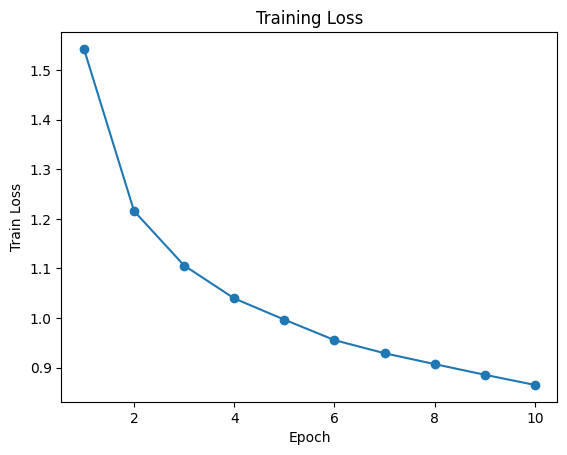

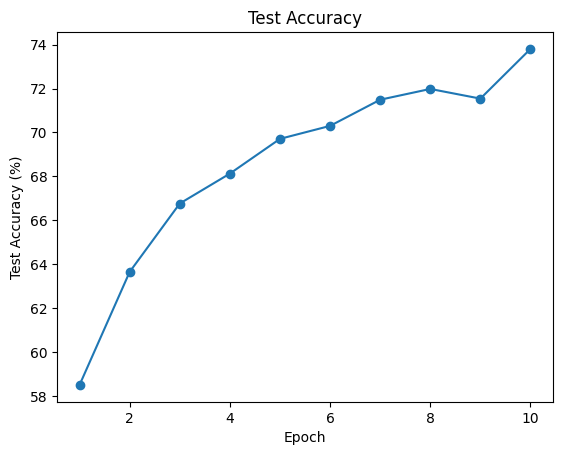

In [11]:
print(train_losses)
print(test_accs)
import matplotlib.pyplot as plt

epochs_range = range(1, len(train_losses) + 1)

plt.figure()
plt.plot(epochs_range, train_losses, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Train Loss")
plt.title("Training Loss")
plt.savefig("train_loss.png")
plt.show()

plt.figure()
plt.plot(epochs_range, test_accs, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Test Accuracy (%)")
plt.title("Test Accuracy")
plt.savefig("test_accuracy.png")
plt.show()


In [8]:
print(model)

NeuralNetwork(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (linear_relu_stack): Sequential(
    (0): Linear(in_features=3072, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=512, bias=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=10, bias=True)
  )
)


学習したモデルを生成している

In [12]:
torch.save(model.state_dict(), "model.pth")
print("Saved PyTorch Model State to model.pth")

Saved PyTorch Model State to model.pth


In [14]:
model = NeuralNetwork().to(device)
model.load_state_dict(torch.load("model.pth", weights_only=True))

classes = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot",
]

model.eval()
x, y = test_data[0][0], test_data[0][1]
with torch.no_grad():
    x = x.to(device)
    pred = model(x)
    predicted, actual = classes[pred[0].argmax(0)], classes[y]
    print(f'Predicted: "{predicted}", Actual: "{actual}"')

RuntimeError: Error(s) in loading state_dict for NeuralNetwork:
	Missing key(s) in state_dict: "linear_relu_stack.0.weight", "linear_relu_stack.0.bias", "linear_relu_stack.2.weight", "linear_relu_stack.2.bias", "linear_relu_stack.4.weight", "linear_relu_stack.4.bias". 
	Unexpected key(s) in state_dict: "conv_stack.0.weight", "conv_stack.0.bias", "conv_stack.3.weight", "conv_stack.3.bias", "fc.1.weight", "fc.1.bias". 